# Grad-CAM : où regardent ResNet18 et le CNN quand ils se trompent ?

Ce notebook :
1. charge les deux modèles et les logits sauvegardés ;
2. choisit des images à examiner (erreurs communes, gliomes prédits « pas de tumeur », témoins) ;
3. trace les cartes Grad-CAM (classe **prédite**, classe **vraie**, carte **signée**) ;
4. mesure, sur les 1 600 images de test, la part de la carte située sur le **fond noir**.


In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from tqdm import tqdm

import torch
import torch.nn.functional as F
from torchvision import datasets

from model import build_model, load_checkpoint, get_target_layer
from dataset import get_transforms
from utils import CLASSES, MODELS, get_device

device = get_device()
NAMES = ["resnet18", "cnn"]

# Modèles (poids entraînés) et jeu de test, avec le prétraitement propre à chaque modèle
nets = {n: load_checkpoint(build_model(n, pretrained=False).to(device),
                           f"../models/{MODELS[n]['checkpoint']}", device).eval() for n in NAMES}
ds = {n: datasets.ImageFolder("../dataset/Testing", transform=get_transforms(n)[1]) for n in NAMES}
assert ds["resnet18"].samples == ds["cnn"].samples      # même ordre d'images pour les deux modèles

# Prédictions à partir des logits sauvegardés (pas besoin de relancer les modèles)
L = {n: np.load(f"../results/{MODELS[n]['logits']}") for n in NAMES}
y = L["resnet18"]["test_y"]
pred = {n: L[n]["test_logits"].argmax(1) for n in NAMES}

groups = {
    "erreurs communes":            np.where((pred["resnet18"] != y) & (pred["cnn"] != y))[0],
    "gliomes prédits notumor":     np.where((y == 0) & (pred["resnet18"] == 2))[0],   # ResNet18
    "bien classées (témoins)":     np.where((pred["resnet18"] == y) & (pred["cnn"] == y))[0],
}
for k, v in groups.items():
    print(f"{k:28s} {len(v):5d} images")

erreurs communes                77 images
gliomes prédits notumor         28 images
bien classées (témoins)       1374 images


## 1. Grad-CAM

Pour une classe `c` et la dernière couche convolutive (cartes d'activation `A^k`, 7×7) :

- `alpha_k = moyenne spatiale du gradient de y^c par rapport à A^k` (importance du canal `k`) ;
- `carte = ReLU( somme_k alpha_k * A^k )`, agrandie à 224×224 puis normalisée dans [0, 1].

Avec `signed=True`, on **supprime la ReLU** et on divise par le maximum en valeur absolue : **rouge = pour la classe, bleu = contre**.

In [2]:
class GradCAM:
    def __init__(self, net, layer):
        self.net, self.act = net, None
        layer.register_forward_hook(lambda m, i, o: setattr(self, "act", o))   # garde les activations A^k

    def __call__(self, x, class_idx=None, signed=False):
        out = self.net(x)
        c = out.argmax(1).item() if class_idx is None else class_idx           # classe expliquée
        grad = torch.autograd.grad(out[0, c], self.act)[0]                     # d y^c / d A^k
        alpha = grad.mean(dim=(2, 3), keepdim=True)                            # alpha_k
        cam = (alpha * self.act).sum(1, keepdim=True)                          # somme_k alpha_k A^k
        if not signed:
            cam = F.relu(cam)
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam / (cam.abs().max() + 1e-8) if signed else (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), out.detach()

cams = {n: GradCAM(nets[n], get_target_layer(nets[n], n)) for n in NAMES}

def load_gray(i, size=224):
    return np.asarray(Image.open(ds["resnet18"].samples[i][0]).convert("L").resize((size, size)), dtype=np.float32) / 255.0

## 2. Figures

`show(indices, modèle, true_class, signed)` : image à gauche, carte superposée à droite. Titre vert = prédiction juste, rouge = erreur.

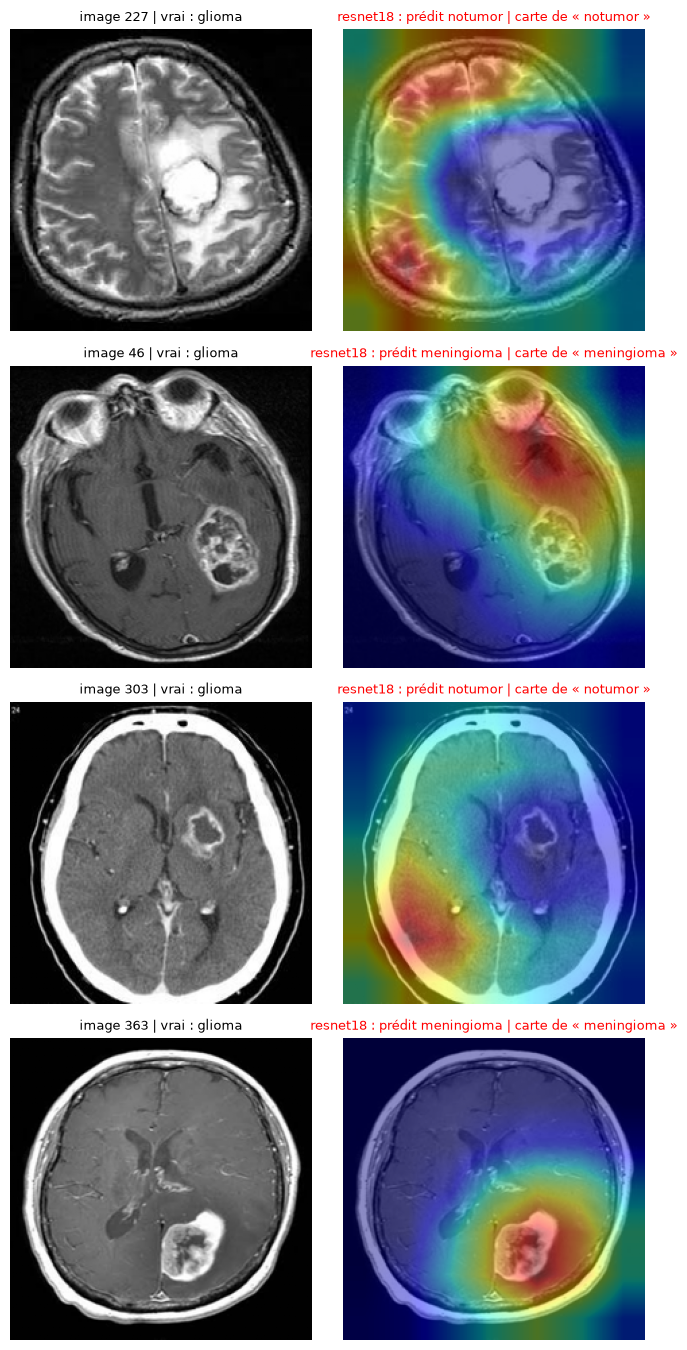

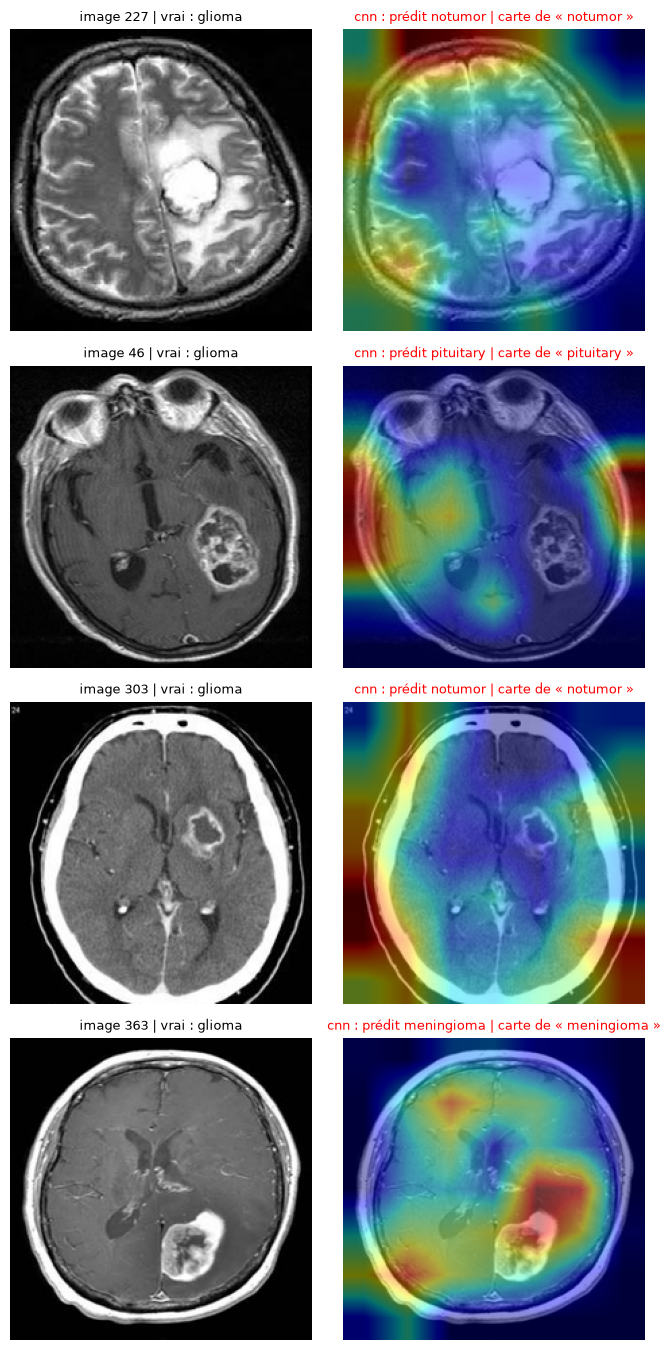

In [3]:
def show(indices, name="resnet18", true_class=False, signed=False):
    fig, axes = plt.subplots(len(indices), 2, figsize=(7, 3.4 * len(indices)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(indices):
        x = ds[name][i][0].unsqueeze(0).to(device)
        heat, out = cams[name](x, class_idx=int(y[i]) if true_class else None, signed=signed)
        shown = int(y[i]) if true_class else int(out.argmax())
        img = load_gray(i)
        kw = dict(cmap="seismic", vmin=-1, vmax=1) if signed else dict(cmap="jet")
        axes[r, 0].imshow(img, cmap="gray")
        axes[r, 0].set_title(f"image {i} | vrai : {CLASSES[y[i]]}", fontsize=9)
        axes[r, 1].imshow(img, cmap="gray"); axes[r, 1].imshow(heat, alpha=0.45, **kw)
        axes[r, 1].set_title(f"{name} : prédit {CLASSES[pred[name][i]]} | carte de « {CLASSES[shown]} »", fontsize=9,
                             color="green" if pred[name][i] == y[i] else "red")
        axes[r, 0].axis("off"); axes[r, 1].axis("off")
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(42)
pick = lambda g, n=4: rng.choice(groups[g], min(n, len(groups[g])), replace=False)

common = pick("erreurs communes")
show(common, "resnet18"); show(common, "cnn")                     # mêmes images, deux modèles

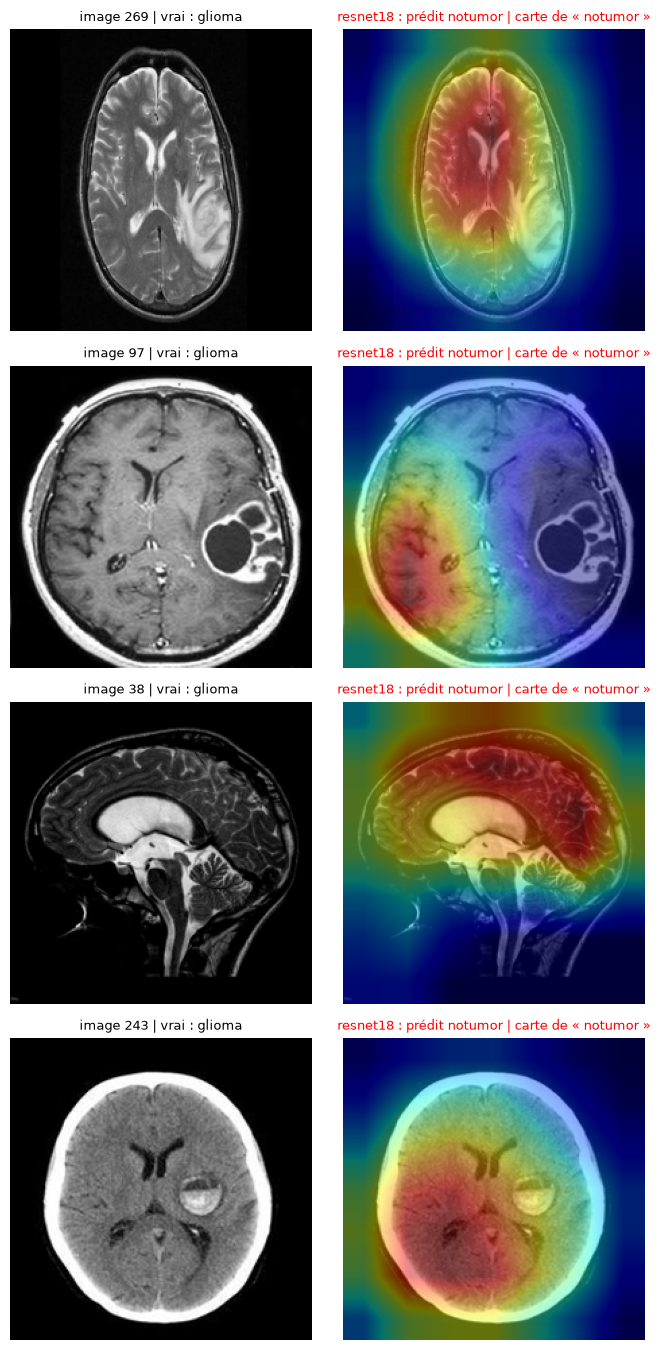

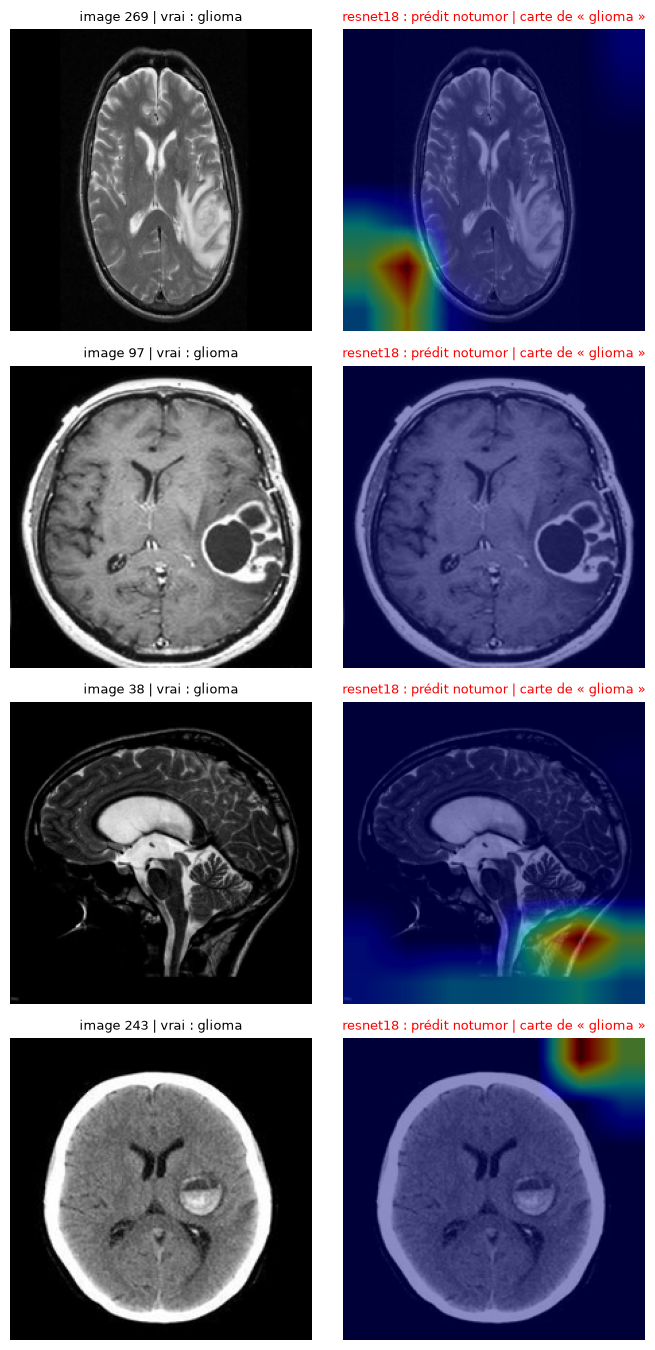

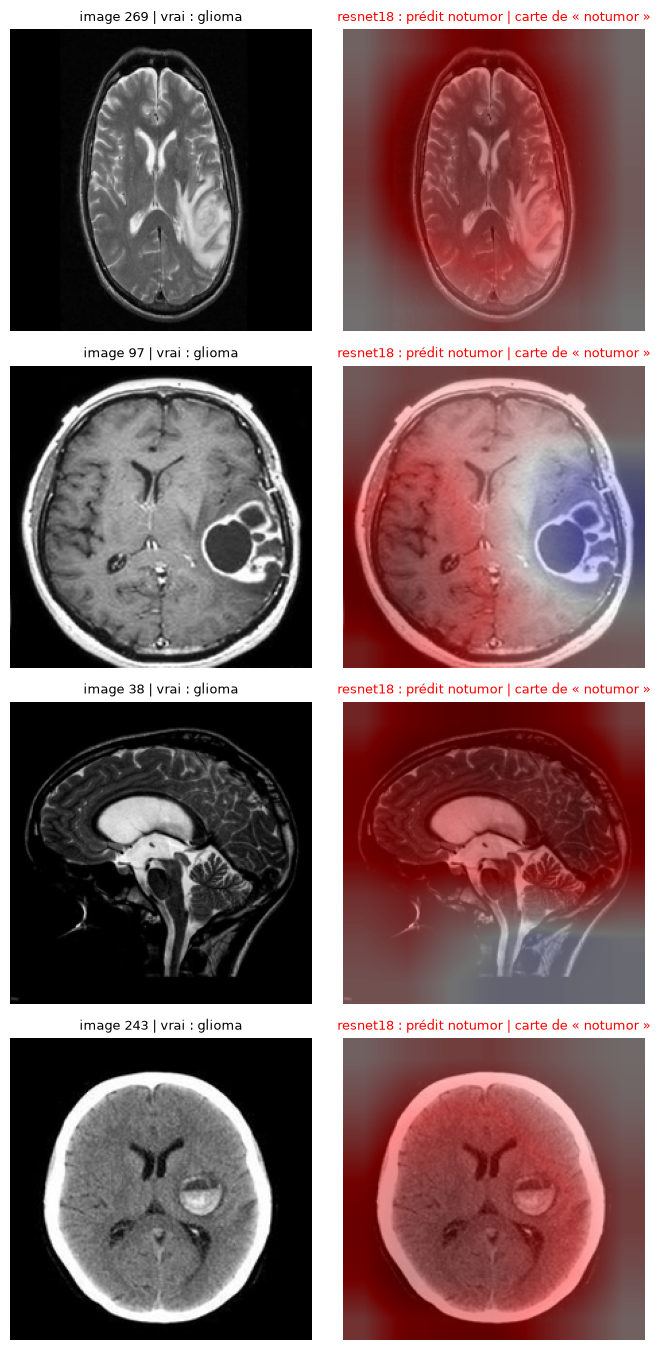

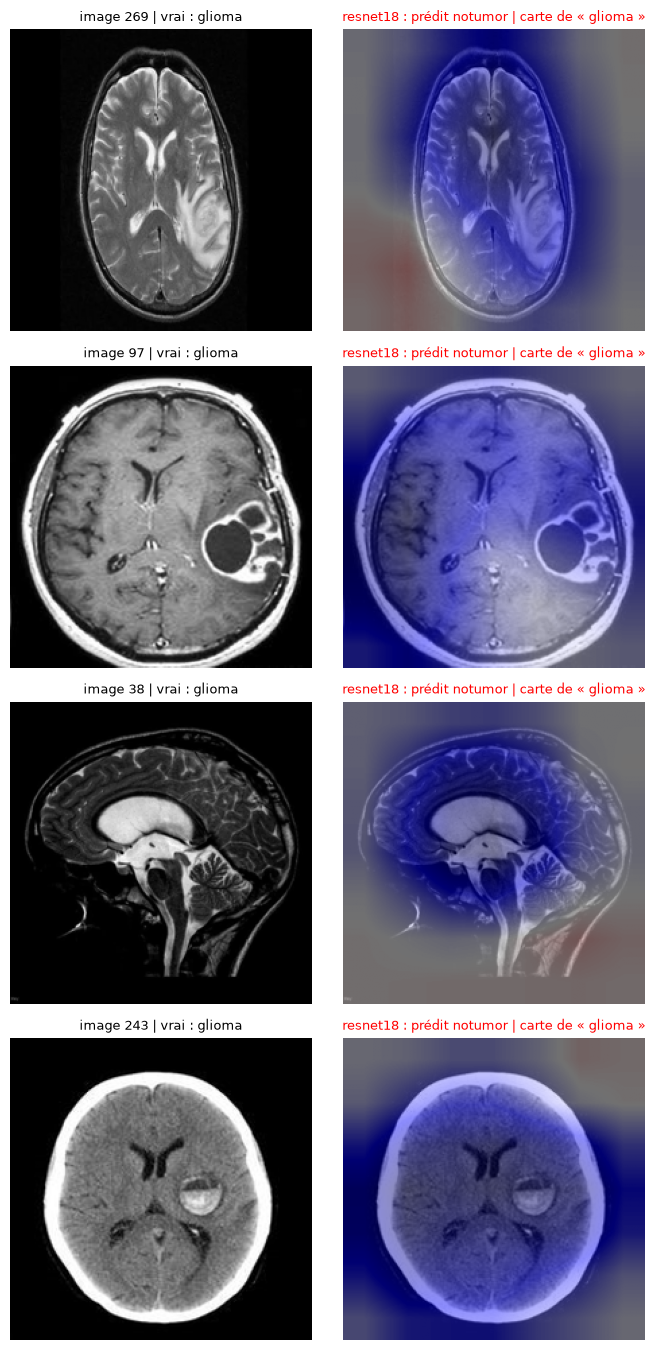

In [4]:
# Gliomes prédits « pas de tumeur » par ResNet18 : classe PRÉDITE, puis VRAIE classe, puis carte SIGNÉE de « notumor » et de « glioma »
g = pick("gliomes prédits notumor")
show(g, "resnet18")                                  # ce qui soutient « notumor »
show(g, "resnet18", true_class=True)                 # ce qui soutient « glioma »
show(g, "resnet18", signed=True)                     # « notumor » avec le signe : bleu = va contre
show(g, "resnet18", true_class=True, signed=True)    # « glioma » avec le signe

## 3. Mesure sur le fond (1 600 images)

On masque la **tête** (seuil + remplissage ; ce n'est pas un masque du cerveau) puis on calcule, pour chaque image :
- `off_cam` : part de la carte Grad-CAM située sur le **fond noir** ;
- `off_area` : part de l'image occupée par le fond (ce que donnerait une carte uniforme : c'est la **référence**).

**Vérifie le masque** (cellule suivante) : si le fond n'est pas parfaitement noir, ajuste `thr`.

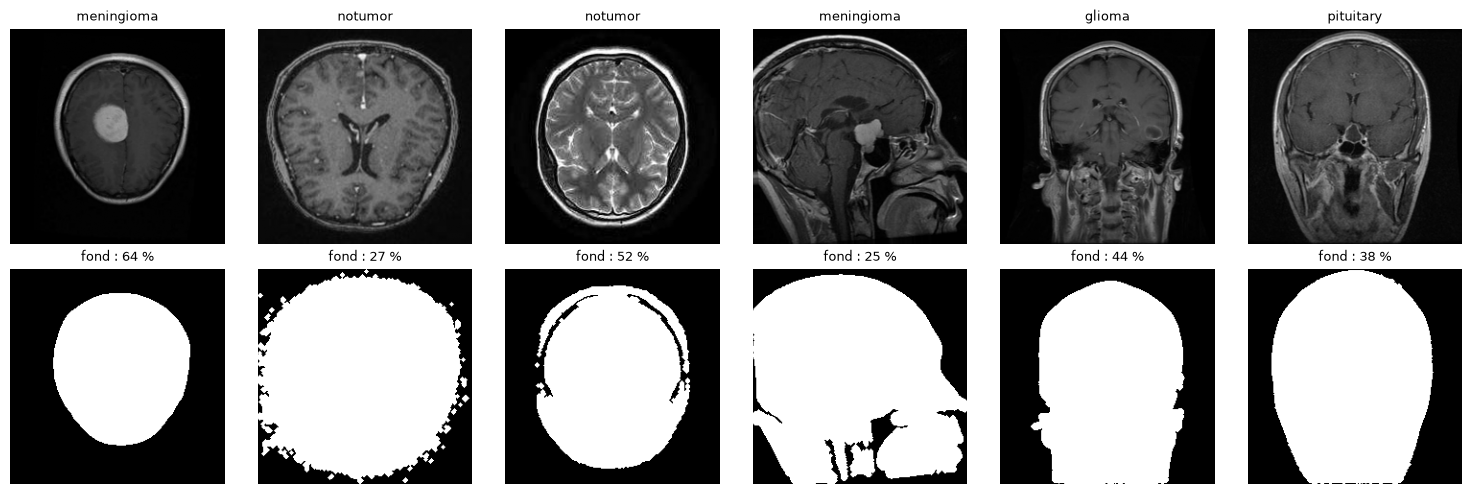

In [5]:
def brain_mask(img01, thr=0.05):
    m = ndimage.binary_opening(img01 > thr, iterations=2)
    return ndimage.binary_fill_holes(m)

sample = np.random.default_rng(0).choice(len(y), 6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, i in enumerate(sample):
    img = load_gray(i); m = brain_mask(img)
    axes[0, j].imshow(img, cmap="gray"); axes[0, j].set_title(CLASSES[y[i]], fontsize=9)
    axes[1, j].imshow(m, cmap="gray");   axes[1, j].set_title(f"fond : {100 * (~m).mean():.0f} %", fontsize=9)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

In [6]:
def cam_stats(name):
    rows = []
    for i in tqdm(range(len(y)), desc=name):
        x = ds[name][i][0].unsqueeze(0).to(device)
        heat, out = cams[name](x)
        m = brain_mask(load_gray(i))
        rows.append({"idx": i, "y": int(y[i]), "pred": int(out.argmax()),
                     "conf": float(F.softmax(out, 1).max()),
                     "off_cam": float(heat[~m].sum() / (heat.sum() + 1e-8)),
                     "off_area": float((~m).mean())})
    return pd.DataFrame(rows)

stats = {n: cam_stats(n) for n in NAMES}
for n in NAMES:
    stats[n].assign(modele=MODELS[n]["display"]).to_csv(f"../results/gradcam_stats_{MODELS[n]['display']}.csv", index=False)

cnn: 100%|███████████████████████████████████████████| 1600/1600 [00:21<00:00, 73.71it/s]


In [7]:
rows = []
for n in NAMES:
    d = stats[n].assign(bien_classee=lambda t: t.pred == t.y, classe=lambda t: [CLASSES[k] for k in t.y])
    for (cls, ok), g in d.groupby(["classe", "bien_classee"]):
        rows.append({"modèle": MODELS[n]["display"], "classe vraie": cls, "bien classée": ok, "n": len(g),
                     "part CAM hors tête (médiane)": g.off_cam.median(), "part image hors tête (médiane)": g.off_area.median()})
summary = pd.DataFrame(rows).round(3)
summary.to_csv("../results/gradcam_summary.csv", index=False)
summary

,modèle,classe vraie,bien classée,n,part CAM hors tête (médiane),part image hors tête (médiane)
0,ResNet18,glioma,False,72,0.146,0.276
1,ResNet18,glioma,True,328,0.248,0.512
2,ResNet18,meningioma,False,16,0.190,0.501
3,ResNet18,meningioma,True,384,0.195,0.446
4,ResNet18,notumor,True,400,0.240,0.398
5,ResNet18,pituitary,False,3,0.179,0.332
6,ResNet18,pituitary,True,397,0.134,0.313
7,CNN,glioma,False,122,0.345,0.392
8,CNN,glioma,True,278,0.567,0.526
9,CNN,meningioma,False,78,0.261,0.370


### Tableaux du rapport

Les deux tableaux de la section 4 du rapport (bien classées contre erreurs ; par classe vraie) se recalculent depuis les CSV :
`off_cam` plus petit que `off_area` = la carte est **moins** sur le fond que ne le ferait le hasard.

In [8]:
from gradcam import report_tables     # fonction de src/gradcam.py (pandas uniquement)
report_tables("../results")


Part de la carte sur le fond, bien classées contre erreurs :
  modèle        groupe    n  off_cam (méd.)  off_area (méd.)  diff. médiane  % images off_cam > off_area
ResNet18 bien classées 1509           0.194            0.422         -0.212                        0.066
ResNet18       erreurs   91           0.157            0.319         -0.126                        6.593
     CNN bien classées 1388           0.322            0.424         -0.085                       23.919
     CNN       erreurs  212           0.312            0.375         -0.035                       35.849

Par classe vraie :
    classe  off_area (méd.)  off_cam ResNet18 (méd.)  ResNet18 : % off_cam > off_area  off_cam CNN (méd.)  CNN : % off_cam > off_area
    glioma            0.486                    0.241                             1.25               0.492                       55.50
meningioma            0.450                    0.194                             0.50               0.339                    